# Appendix: Historical USDC Yield and Withdrawal Liquidity

**Aave V3 Ethereum Core and two Morpho V1 vaults** · 1 June 2024–15 October 2026 UTC

- **Morpho · Steakhouse V1:** 4.68% annualized native return, versus **4.61%** for Aave. Over the full holding period, the difference was **+16 USDC per 10,000 initially supplied**.
- **Morpho · Gauntlet Prime V1:** 4.72% annualized native return, versus **4.61%** for Aave. Over the full holding period, the difference was **+27 USDC per 10,000 initially supplied**.
- **Aave’s minimum sampled cash was 6,519 USDC**, at 21 April 2026 00:00 UTC. This illustrates liquidity risk even when the supply-income index keeps rising.
- **Withdrawal capacity is a separate outcome.** The figures show the cash that could be reached at each sampled block, not a guarantee of execution or an estimate of default probability.

An unleveraged-supplier case study. Returns are measured in **USDC, not guaranteed US dollars**. This comparison does not establish which protocol is safest.

## 1. What is being compared?

Aave pools USDC against protocol-approved collateral. A Morpho V1 vault places USDC into selected isolated lending markets; its curator chooses the allocations. In both designs, borrowers pay interest, and cash lent out is not simultaneously available for suppliers to withdraw.

The two Morpho products were chosen for their long histories, not their observed return ranking. **This is a comparison of these contracts, not all of Aave versus all of Morpho.**

| Product | Exact contract / primary source | Version |
|---|---|---|
| Aave Ethereum Core USDC | [aUSDC](https://etherscan.io/address/0x98C23E9d8f34FEFb1B7BD6a91B7FF122F4e16F5c#code) · [Pool](https://etherscan.io/address/0x87870Bca3F3fD6335C3F4ce8392D69350B4fA4E2#code) | V3 |
| Morpho Steakhouse USDC | [Vault](https://etherscan.io/address/0xBEEF01735c132Ada46AA9aA4c54623cAA92A64CB#code) | V1 |
| Morpho Gauntlet USDC Prime | [Vault](https://etherscan.io/address/0xdd0f28e19C1780eb6396170735D45153D261490d#code) | V1 |

**Data and protocol:** [full source catalogue](../docs/DATA_SOURCES.md) · [design committed before panel collection](../docs/PROTOCOL.md) · [collection code](../collect.py) · [accounting and plotting code](../analyse.py).

### Key assumptions

- Existing unleveraged positions; no borrowing, recursive leverage or switching between products.
- Native interest after vault fees; separately distributed token incentives, gas and taxes are excluded. Cost scenarios appear separately below.
- Withdrawals use the historical standard withdrawal route, with no new deposits or repayments assumed. Other users can compete for the same liquidity.
- Daily snapshots plus six-hour snapshots around three predefined sell-offs. Snapshots cannot establish the worst condition between observations.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'analyse.py').exists():
    raise RuntimeError('Run this notebook from the repository root or its notebooks directory.')
sys.path.insert(0, str(ROOT))
from analyse import load_panel, summarize, build_figures, NAMES
panel, daily, eth = load_panel()  # verifies hashes, blocks and accounting; no network calls
summary, events, stress_days = summarize(panel, daily, eth)
figures = build_figures(panel, daily, eth, summary)

### Coverage and traceability

The panel contains **867 daily observations per product**, plus additional six-hour observations in the three stress windows, for **957 common block snapshots**. All three products are read at the same block. There is no forward filling of missing states.

For each anchor we verify that the selected block occurred at or before the requested time and that the following block occurred after it. The table below gives a few directly inspectable observations; the full files retain every call and response.

In [2]:
example = daily[daily['product'].eq('aave')].iloc[[0, len(daily)//6, -1]][['date','block','raw_file']].copy()
example['On-chain block'] = example['block'].map(lambda n: f'https://etherscan.io/block/{n}')
example['Saved calls'] = example['raw_file'].map(lambda p: f'../{p}')
for row in example.itertuples(index=False):
    display(Markdown(f"{row.date:%Y-%m-%d}: [Ethereum block {row.block}]({row[3]}) · [saved contract reads]({row[4]})"))

2024-06-01: [Ethereum block 19993249](https://etherscan.io/block/19993249) · [saved contract reads](../data/raw/states/1717200000.json.gz)

2025-08-08: [Ethereum block 23092619](https://etherscan.io/block/23092619) · [saved contract reads](../data/raw/states/1754611200.json.gz)

2026-10-15: [Ethereum block 26194188](https://etherscan.io/block/26194188) · [saved contract reads](../data/raw/states/1792022400.json.gz)

## 2. How return and liquidity are measured

**Earned native return** is the ratio of Aave's normalized supply-income index, or Morpho's fee-aware redemption value per fixed number of shares. We do not average advertised APYs to claim an earned return.

For 10,000 initial USDC: `interest = 10,000 × (ending index / starting index − 1)`.

**Withdrawal capacity** is the lesser of available cash and supplier claims. For Morpho we reconstruct each historical withdrawal queue and sum the available portion of the vault's claims in its underlying markets. We reconcile the reconstructed holdings to `totalAssets()` at every sampled block. Separate Morpho vaults may access the same market cash, so their capacities must not be added together.

**Collective withdrawal coverage** is `min(1, capacity / requested withdrawal)`, with no new funds arriving. A shortfall means insufficient immediate cash under that static scenario; it does **not** mean depositors necessarily lost principal.

Accounting references: [Aave Pool](https://aave.com/docs/aave-v3/smart-contracts/pool) · [Morpho V1 withdrawal and fee logic](https://github.com/morpho-org/metamorpho/blob/ded84e59668155b34d3c24906c4f7461c12828af/src/MetaMorpho.sol).

## 3. Yield and available cash

The first figure separates the interest accumulated over the holding period from changes in the earning rate. Annualized trailing returns are backward-looking measurements, not future yield promises.

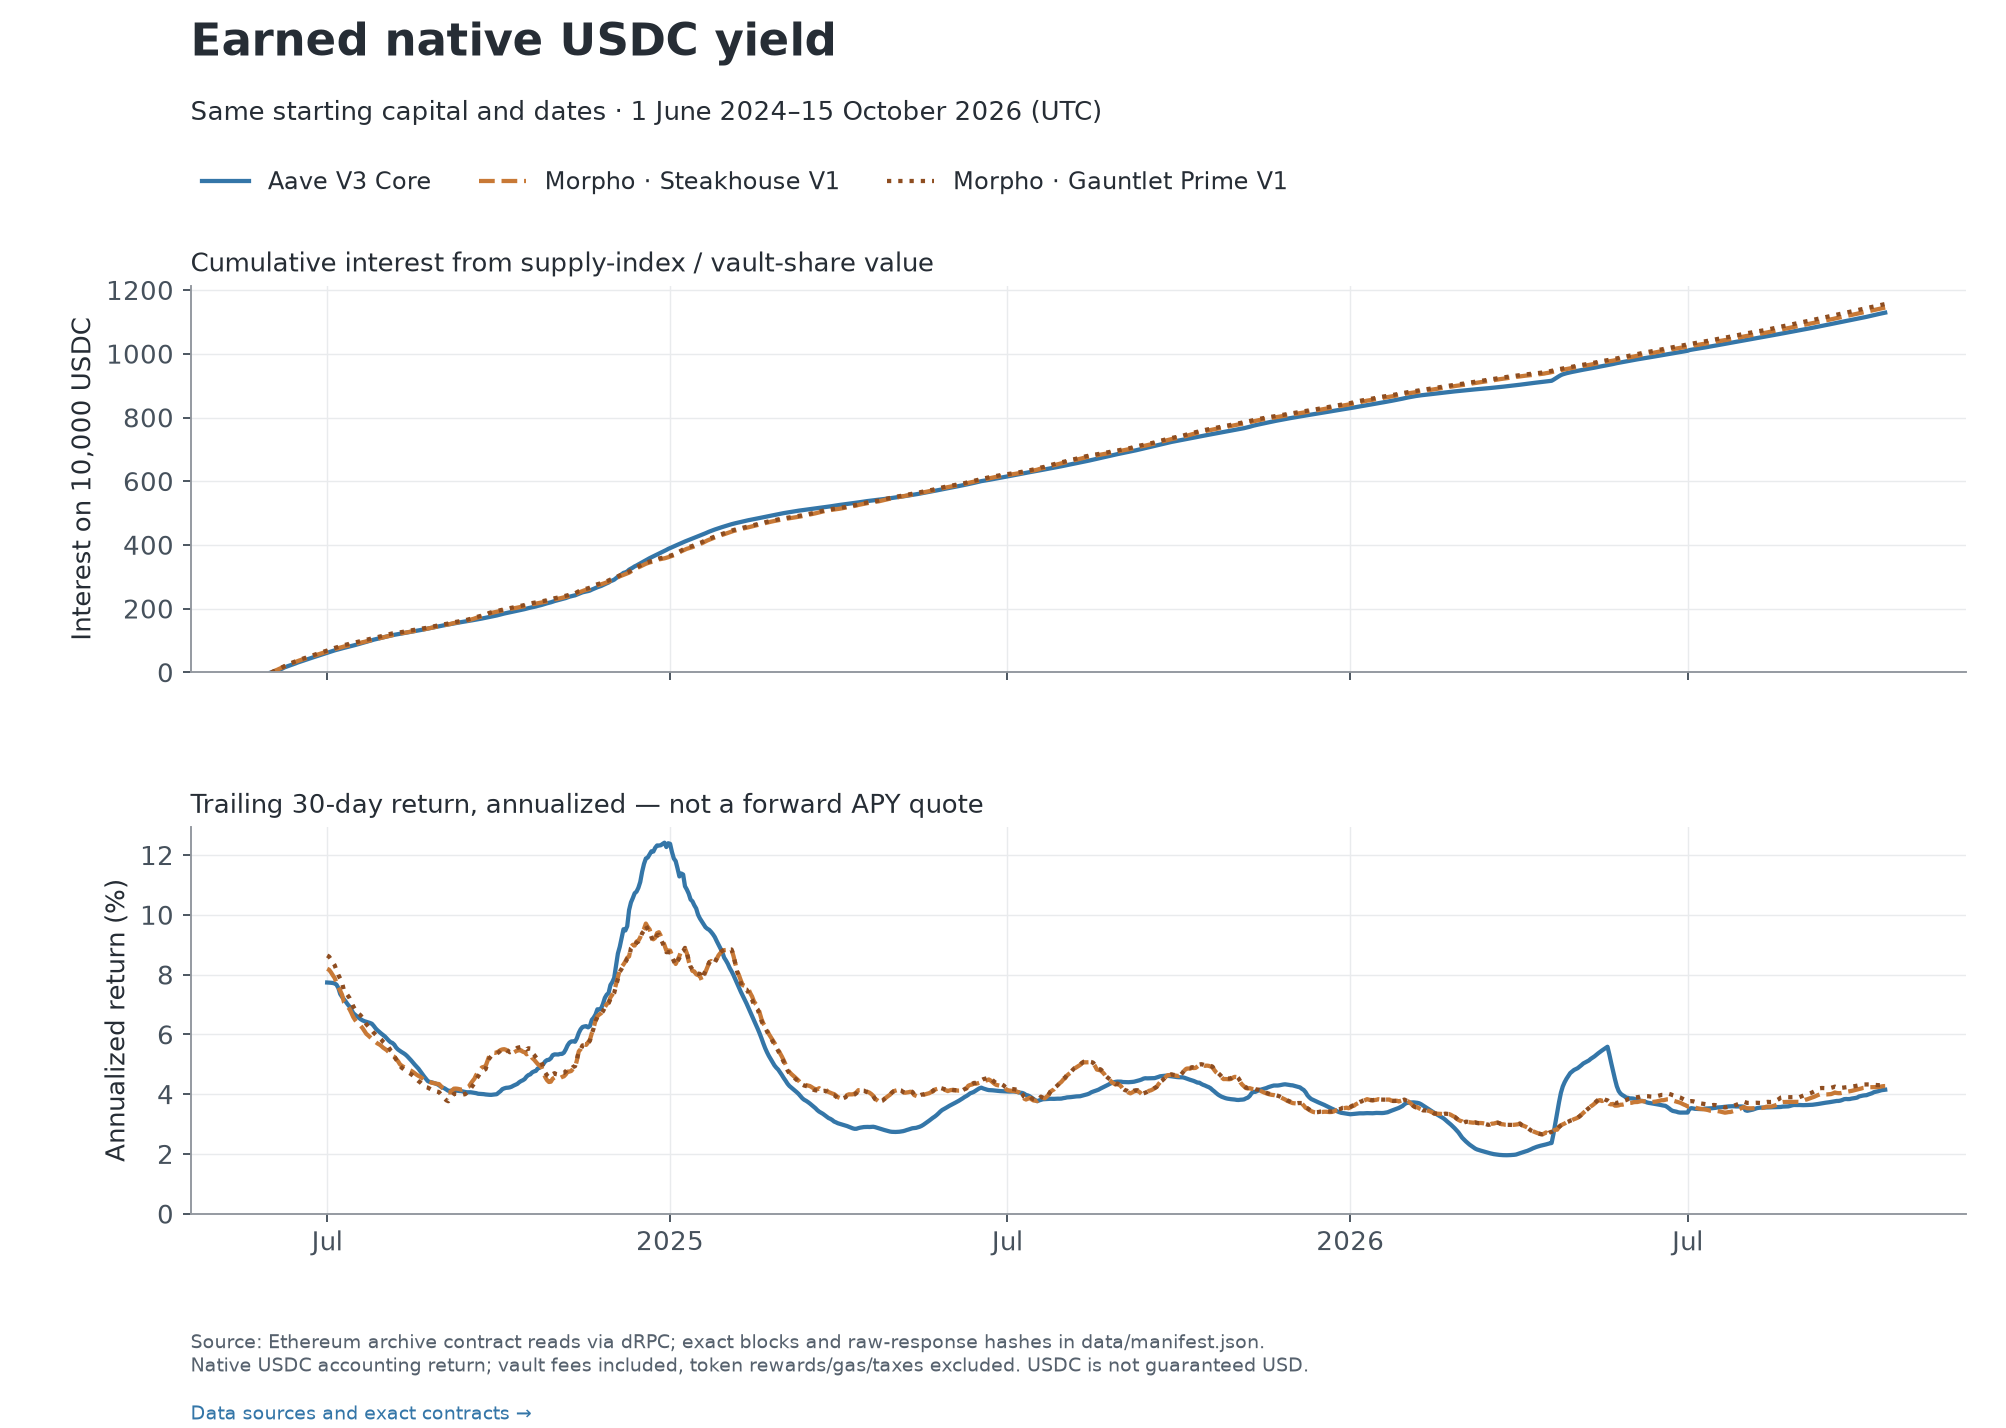

In [3]:
display(Image(filename=str(figures[0]), alt='Cumulative native USDC interest and trailing annualized returns for Aave and two Morpho V1 vaults.'))

**Sources:** [Ethereum contract reads](../docs/DATA_SOURCES.md#products-and-direct-links) · [Raw-data manifest](../data/manifest.json) · [Daily data with block links/identifiers](../data/processed/daily_panel.csv).

In [4]:
table = summary[['name','annualized_return_pct','interest_per_10000','liquidity_median_pct','liquidity_min_pct']].copy()
table.columns = ['Product','Annualized native return (%)','Interest / 10,000 USDC','Median cash / claims (%)','Minimum cash / claims (%)']
display(table.set_index('Product').style.format('{:,.2f}').format({'Minimum cash / claims (%)':'{:.4f}'}))

,Annualized native return (%),"Interest / 10,000 USDC",Median cash / claims (%),Minimum cash / claims (%)
Product,,,,
Aave V3 Core,4.612721,1129.258694,14.945343,0.0003
Morpho · Steakhouse V1,4.675637,1145.145854,24.011882,2.3644
Morpho · Gauntlet Prime V1,4.719877,1156.324866,59.147751,6.8943


The percentage panel makes different product sizes comparable; the absolute panel addresses whether a fixed-size withdrawal could be served. Neither quantity represents a personal reservation of liquidity.

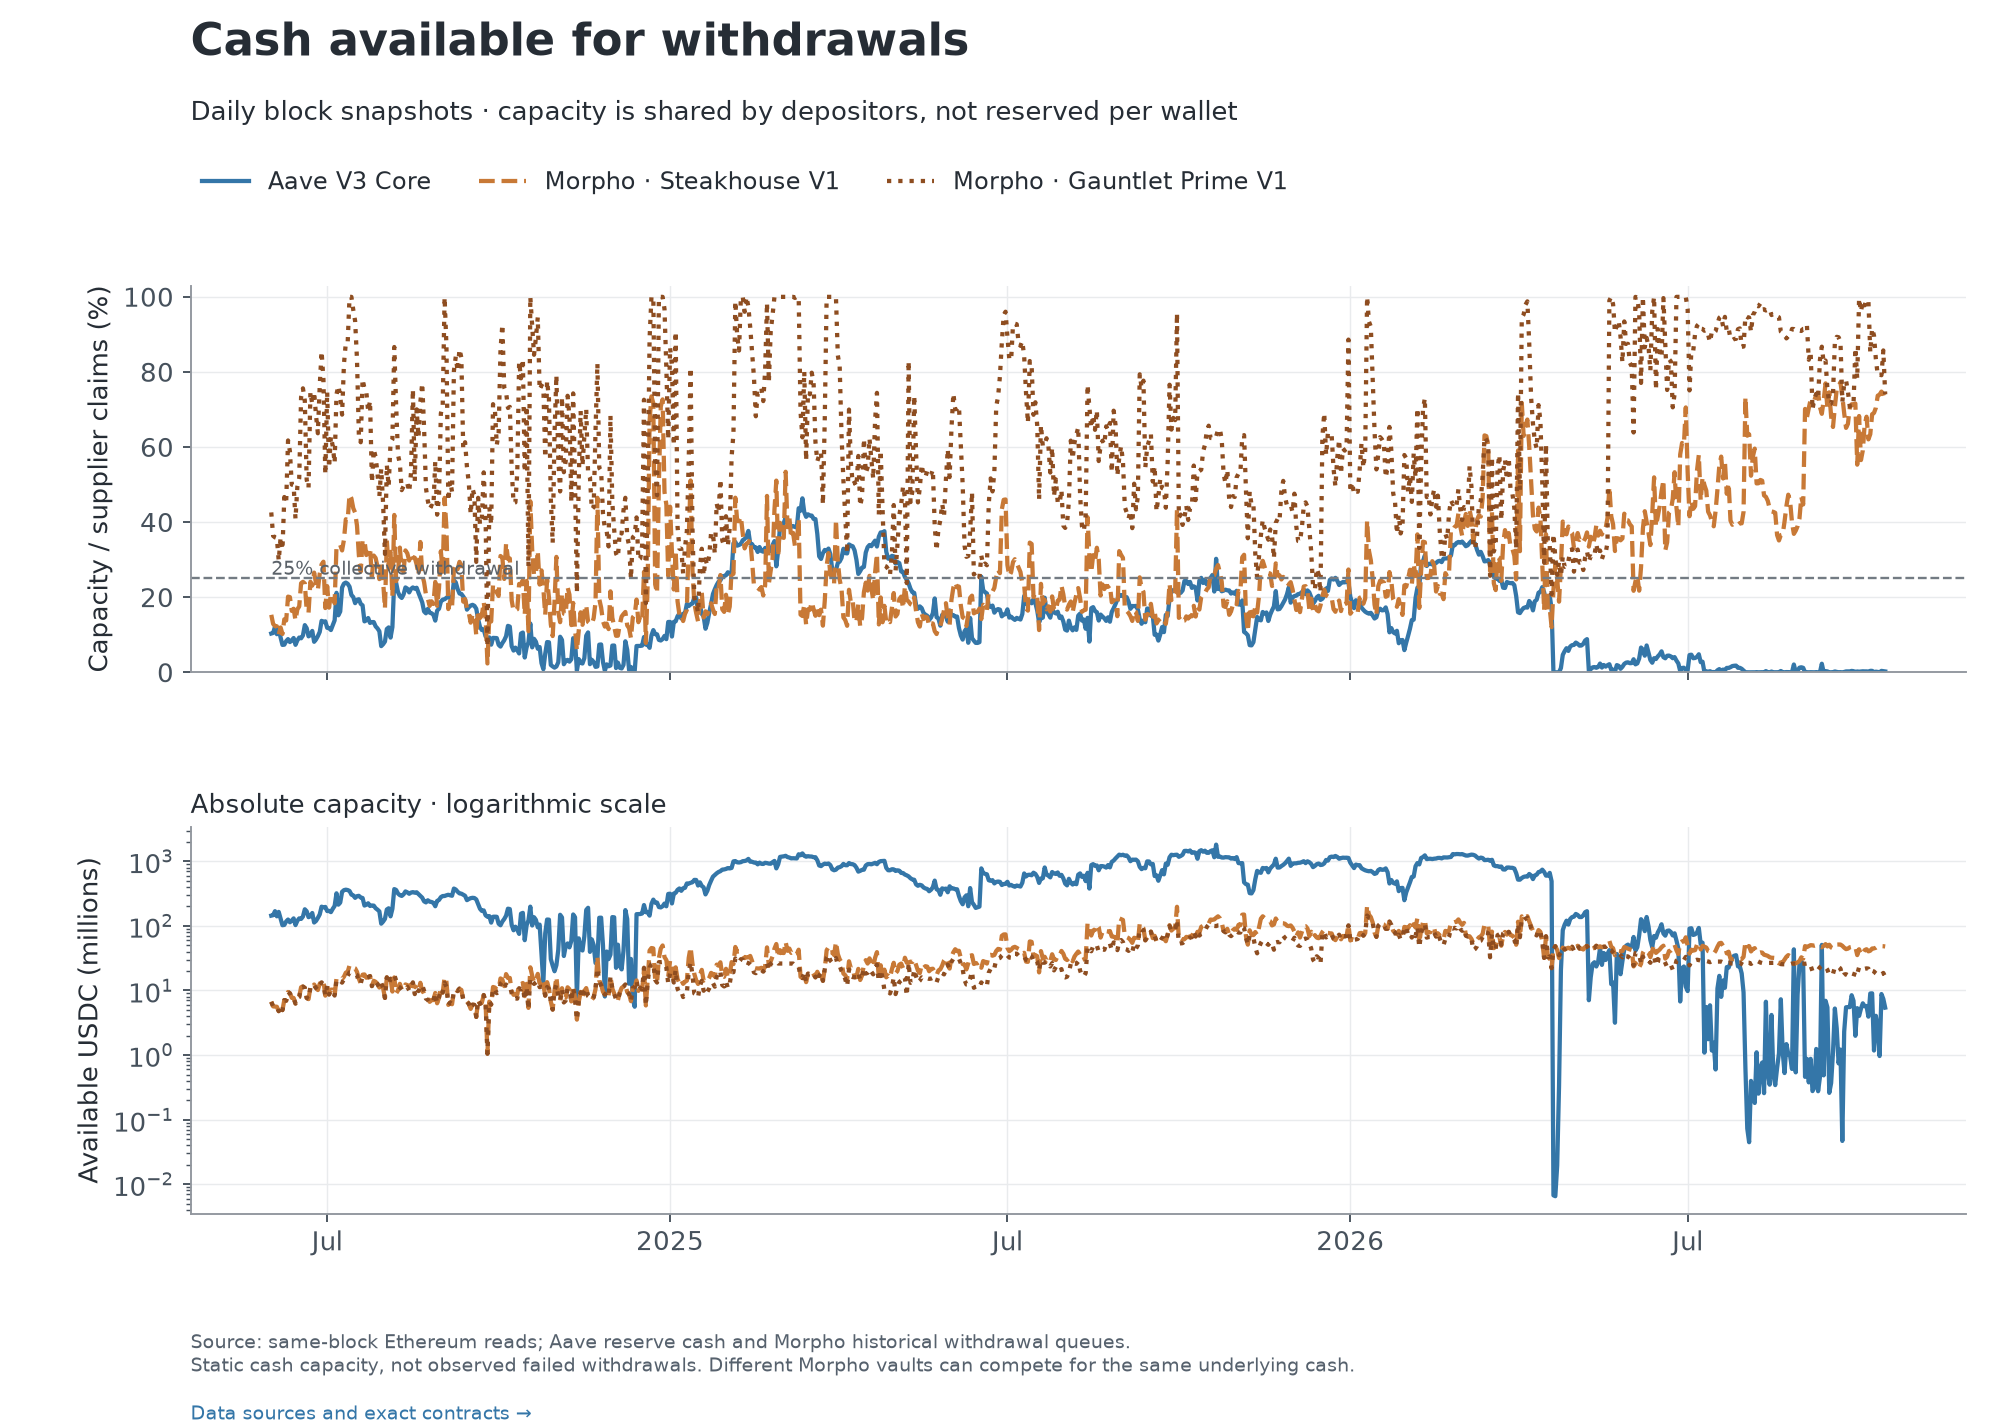

In [5]:
display(Image(filename=str(figures[1]), alt='Historical withdrawal capacity as a share of supplier claims and in absolute USDC; the absolute panel uses a logarithmic scale.'))

**Sources:** [Ethereum contract reads](../docs/DATA_SOURCES.md#products-and-direct-links) · [Raw-data manifest](../data/manifest.json) · [Daily data with block links/identifiers](../data/processed/daily_panel.csv).

**Reading the 25% line:** below it, a simultaneous request for one quarter of all supplier claims exceeds the available cash at that snapshot. It does not show that any actual withdrawal failed.

## 4. What happened during market stress?

These three retrospective event windows were fixed before inspecting the comparative history. The gray lines show ETH market conditions; the colored lines show withdrawal capacity. Liquidations and debt repayments can replenish cash, while supplier exits can reduce it—an asset-price sell-off need not create a lender liquidity squeeze.

Event context: [August 2024](https://www.coinbase.com/institutional/research-insights/research/weekly-market-commentary/weekly-2024-08-09) · [April 2025](https://www.coinbase.com/institutional/research-insights/research/weekly-market-commentary/weekly-2025-04-11) · [October 2025](https://www.coinbase.com/en-de/institutional/research-insights/research/weekly-market-commentary/weekly-2025-10-17). These links establish the market events, not the results for our products.

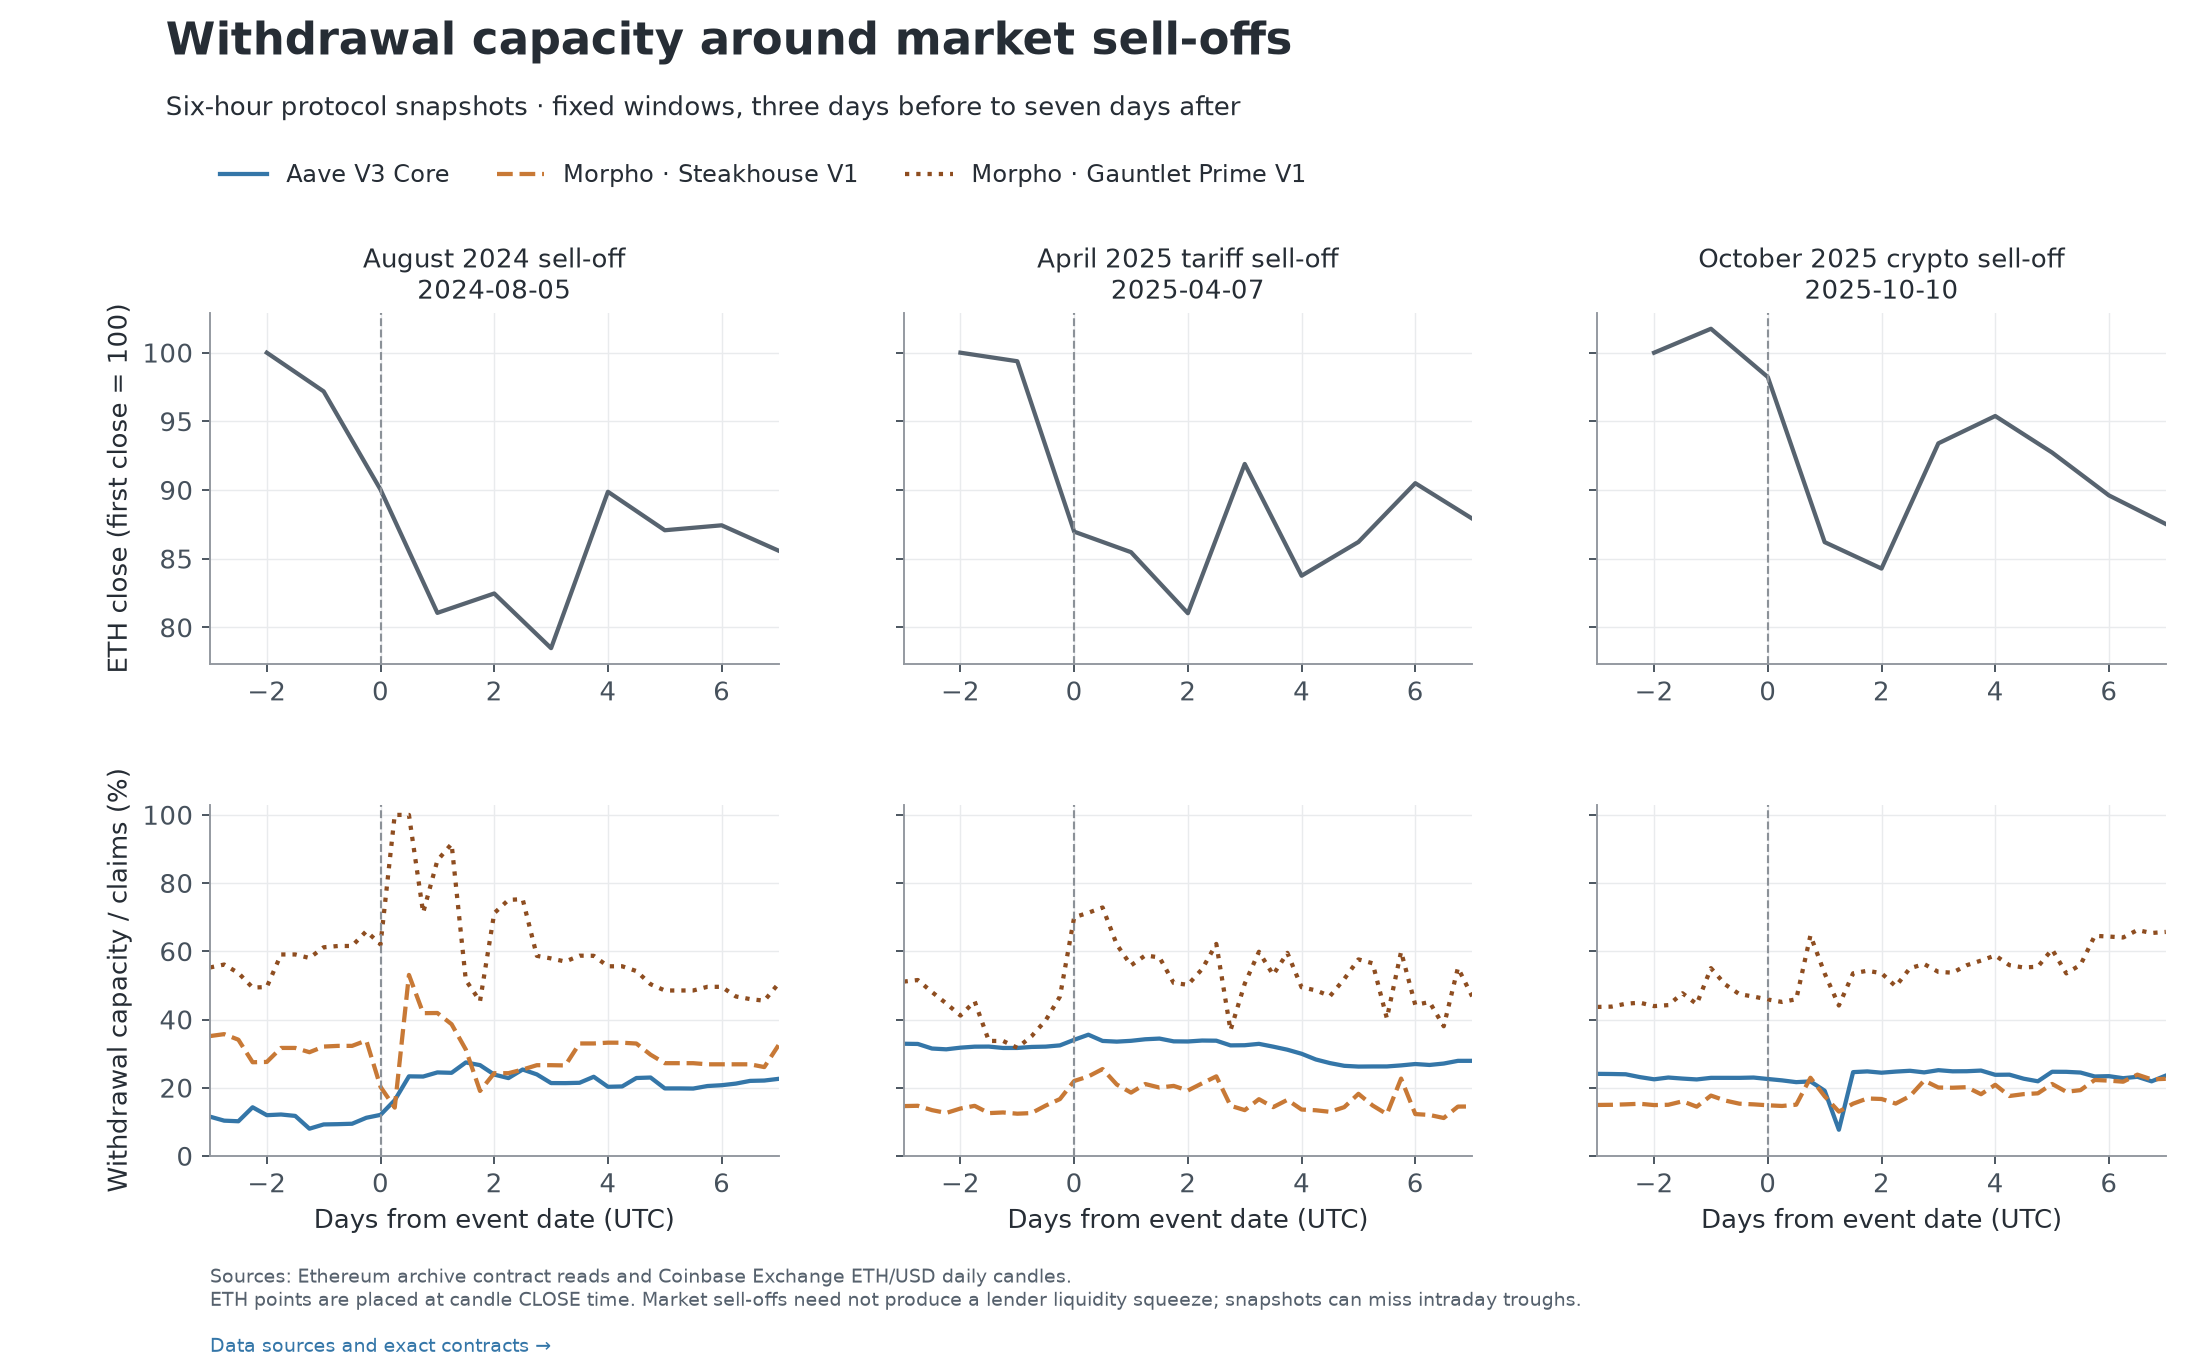

In [6]:
display(Image(filename=str(figures[2]), alt='ETH prices and withdrawal capacity around three preselected sell-offs in August 2024, April 2025 and October 2025.'))

**Sources:** [Ethereum contract reads](../docs/DATA_SOURCES.md#products-and-direct-links) · [Raw-data manifest](../data/manifest.json) · [Daily data with block links/identifiers](../data/processed/daily_panel.csv). · [Coinbase ETH/USD candle data](https://api.exchange.coinbase.com/products/ETH-USD/candles?granularity=86400) · [saved requests and candles](../data/raw/prices).

In [7]:
event_table = events.pivot(index='event_date', columns='product', values='minimum_liquidity_pct').rename(columns=NAMES)
event_table.index.name = 'Event date (10-day window)'
display(Markdown('**Lowest sampled cash / claims in each event window (%)**'))
display(event_table.style.format('{:.1f}'))

**Lowest sampled cash / claims in each event window (%)**

product,Aave V3 Core,Morpho · Gauntlet Prime V1,Morpho · Steakhouse V1
Event date (10-day window),,,
2024-08-05,8.0,45.4,14.2
2025-04-07,26.2,31.7,11.1
2025-10-10,7.7,43.7,13.0


### An additional liquidity event found in the full history

The minimum Aave cash observation was **6,519 USDC at 21 April 2026 00:00 UTC**, against approximately **2.10 billion USDC of supplier claims**. At that block, the two selected Morpho vaults each had roughly 48 million USDC of individually accessible capacity. This is a liquidity comparison, not evidence of an Aave USDC principal loss or independently additive Morpho cash.

The timing coincides with the documented [April 2026 rsETH incident](https://governance.aave.com/t/rseth-incident-report-april-20-2026/24580). This zoom was selected **after** seeing the historical minimum; it is not one of the three preselected tests. The cash observation was independently verified through a second RPC provider. [Diagnostic provenance](../docs/EXPLORATORY_DIAGNOSTIC.md).

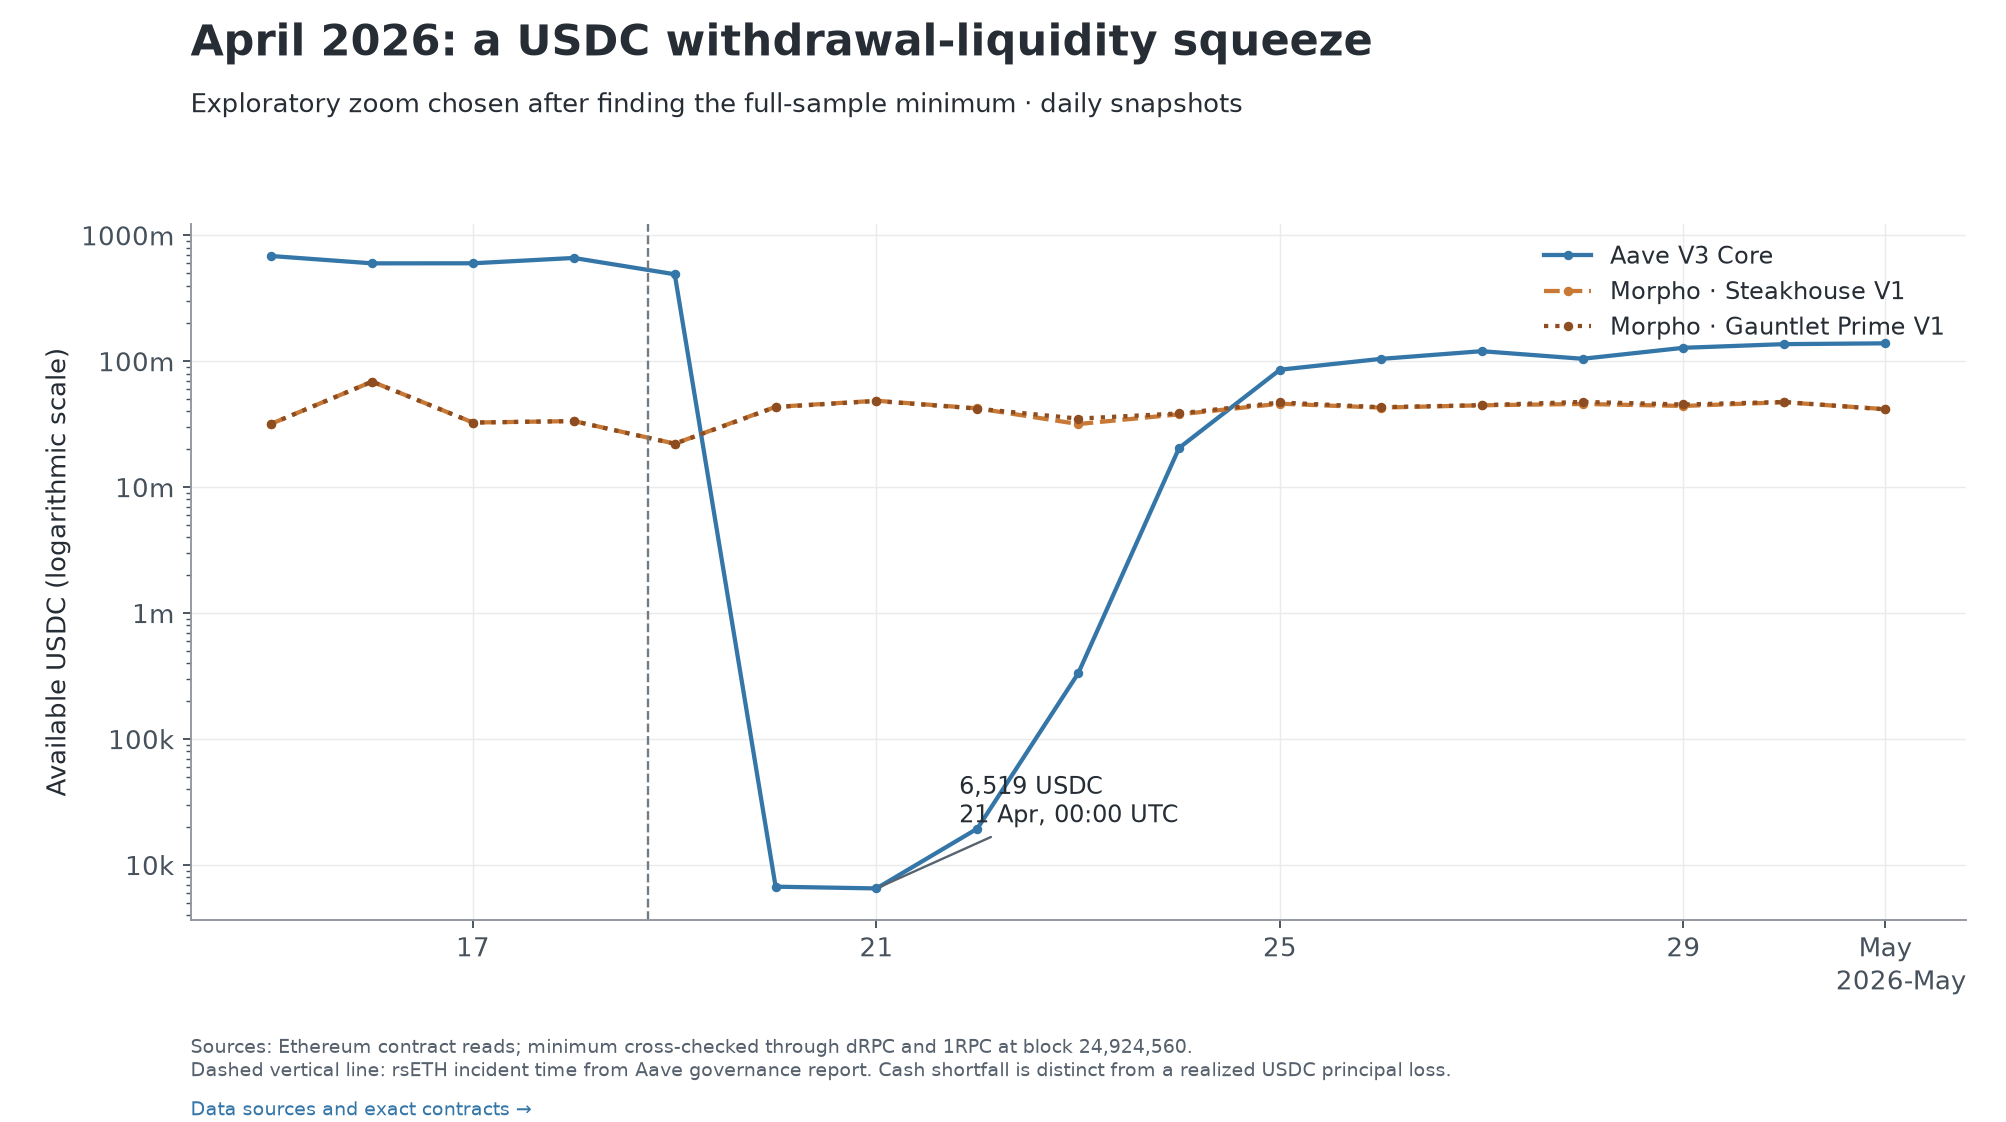

In [8]:
display(Image(filename=str(figures[4]), alt='Exploratory April 2026 liquidity comparison: Aave USDC cash reached a sampled minimum of 6,519 USDC on April 21.'))

**Sources:** [Ethereum contract reads](../docs/DATA_SOURCES.md#products-and-direct-links) · [Raw-data manifest](../data/manifest.json) · [Daily data with block links/identifiers](../data/processed/daily_panel.csv). · [Independent read at block 24,924,560](../data/raw/crosschecks/aave_minimum_1rpc.io.json).

To avoid relying only on the selected examples, the next table includes **every covered daily ETH decline of at least 7%**. It pairs the day’s close-to-close return with cash at the end of that day. The initial anchor lacks a prior daily return and is excluded from this classification. This is descriptive co-occurrence, not a prediction or causal test.

In [9]:
regimes = stress_days.copy()
regimes['Product'] = regimes['product'].map(NAMES)
regimes = regimes.rename(columns={'regime':'Market day','n':'Observations','median_capacity_pct':'Median cash / claims (%)','below_25pct_count':'Snapshots below 25% cash'})
display(regimes.set_index(['Product','Market day'])[['Observations','Median cash / claims (%)','Snapshots below 25% cash']].style.format({'Median cash / claims (%)':'{:.1f}'}))

## 5. Was the extra yield worth the liquidity trade-off?

This curve answers a narrower, measurable question: on what share of sampled days was there enough cash to meet a request of a given size? It describes the historical sample; it is not a future probability of withdrawal failure or default.

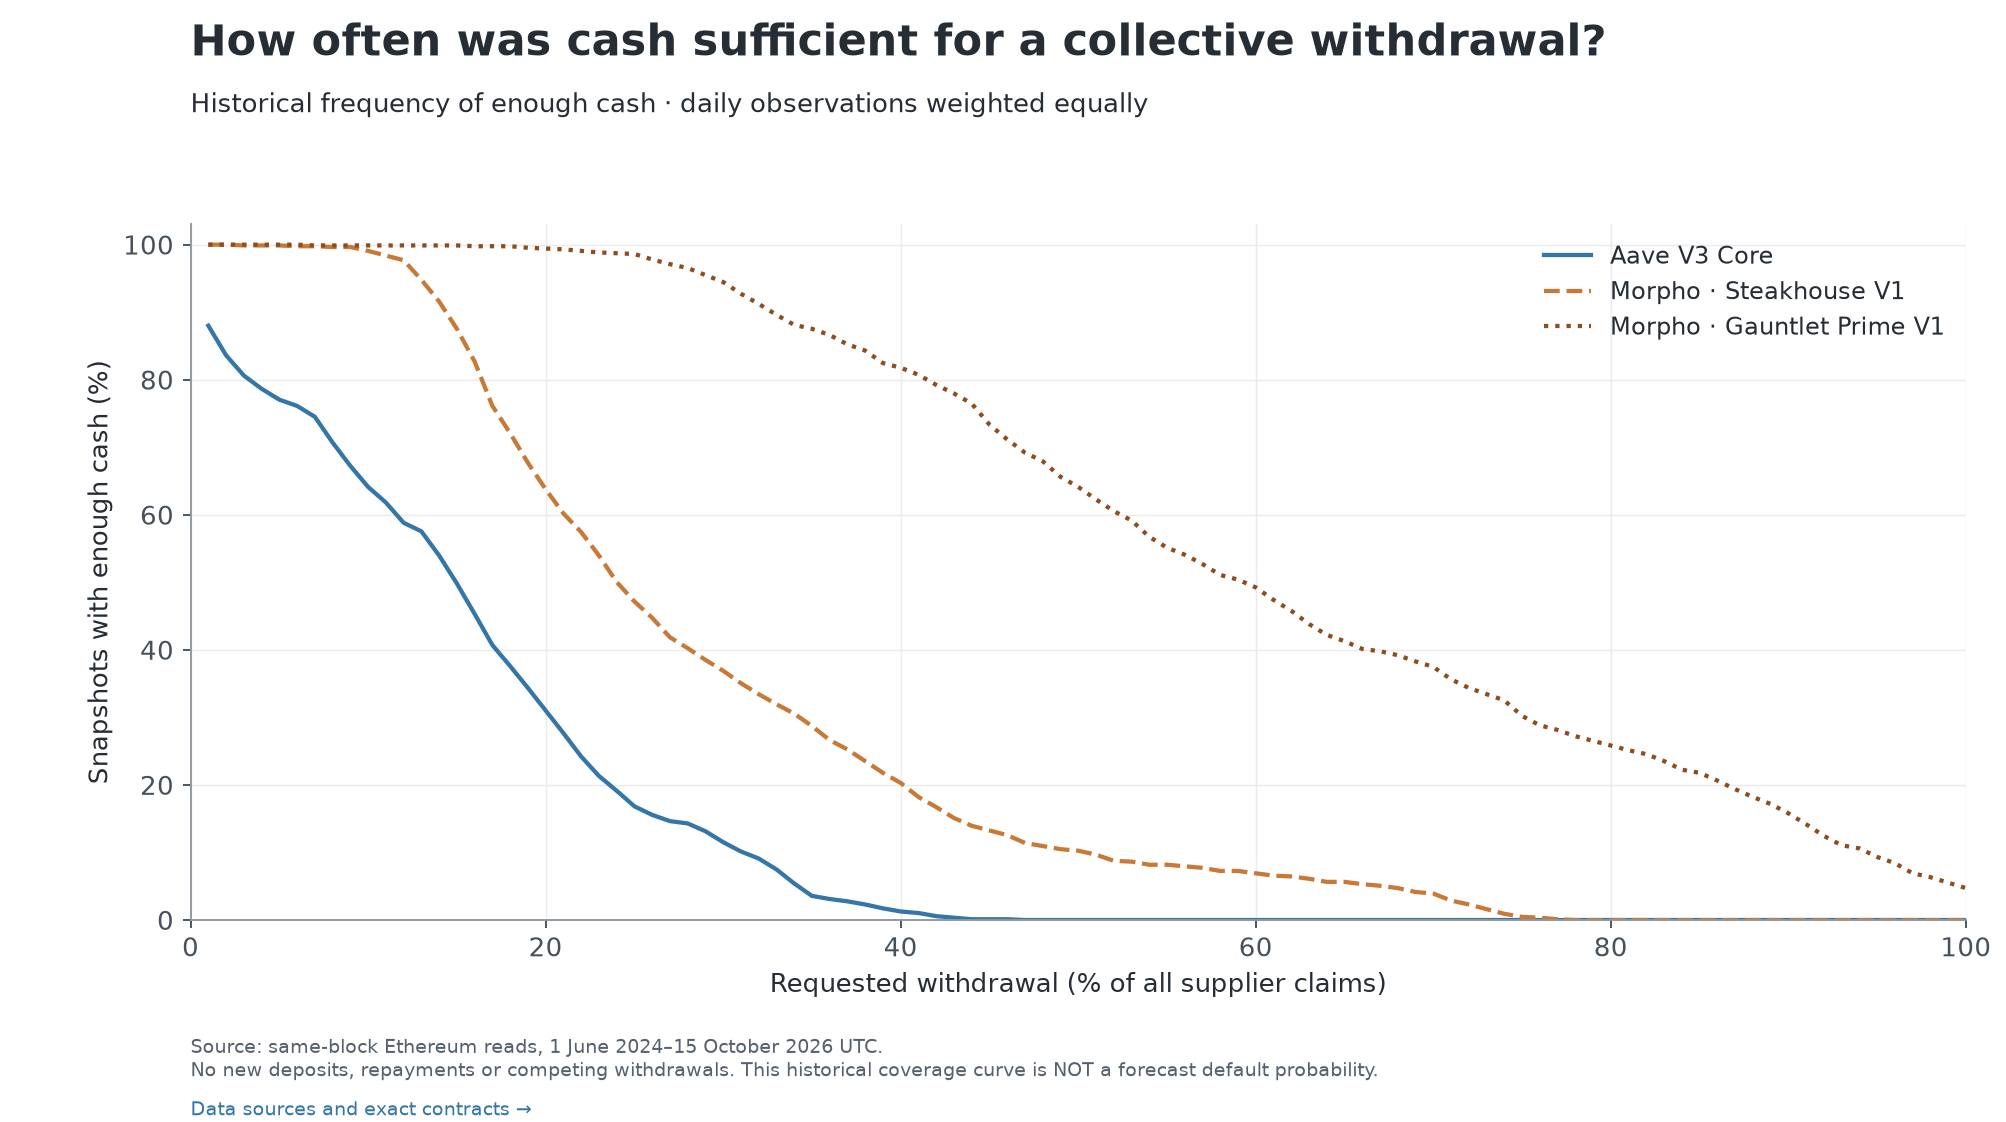

In [10]:
display(Image(filename=str(figures[3]), alt='Share of daily observations with enough cash to meet different collective withdrawal sizes; historical coverage, not a forecast probability.'))

**Sources:** [Ethereum contract reads](../docs/DATA_SOURCES.md#products-and-direct-links) · [Raw-data manifest](../data/manifest.json) · [Daily data with block links/identifiers](../data/processed/daily_panel.csv).

In [11]:
fixed = summary[['name','minimum_capacity_usdc','capacity_below_10000_count','capacity_below_100000_count','capacity_below_1000000_count']].copy()
fixed.columns = ['Product','Minimum available USDC','Below 10,000 USDC','Below 100,000 USDC','Below 1,000,000 USDC']
display(Markdown('**Daily snapshots with insufficient cash for a fixed-size request** — count, not an observed failed transaction.'))
display(fixed.set_index('Product').style.format({'Minimum available USDC':'{:,.0f}'}))

**Daily snapshots with insufficient cash for a fixed-size request** — count, not an observed failed transaction.

,Minimum available USDC,"Below 10,000 USDC","Below 100,000 USDC","Below 1,000,000 USDC"
Product,,,,
Aave V3 Core,"6,519",2,6,38
Morpho · Steakhouse V1,"1,049,921",0,0,0
Morpho · Gauntlet Prime V1,"1,049,921",0,0,0


### Put the premium in money terms

The extra interest column compares the same 10,000-USDC starting balance and holding dates. The haircut column is the hypothetical one-off reduction in the final Morpho balance that would erase its measured premium over Aave. It is **not** an estimated probability or expected loss. It also does not assume Aave is risk-free.

Gas assumptions below are total round-trip costs per position, expressed in USDC. If both products incur identical costs, their relative premium is unchanged; only **additional** costs erase the premium.

In [12]:
premium = summary.loc[['steakhouse_v1','gauntlet_v1'], ['name','extra_interest_vs_aave','terminal_haircut_erasing_premium_pct']].copy()
premium.columns = ['Product','Extra interest vs Aave (USDC)','Terminal haircut erasing premium (%)']
display(premium.set_index('Product').style.format('{:.2f}'))
costs = pd.DataFrame({f'{c} USDC round-trip cost': summary.interest_per_10000-c for c in [0,20,100]})
costs.index = costs.index.map(NAMES)
display(Markdown('**Net earned interest on 10,000 initial USDC, after illustrative execution costs**'))
display(costs.style.format('{:,.0f}'))

,Extra interest vs Aave (USDC),Terminal haircut erasing premium (%)
Product,,
Morpho · Steakhouse V1,15.89,0.14
Morpho · Gauntlet Prime V1,27.07,0.24


**Net earned interest on 10,000 initial USDC, after illustrative execution costs**

,0 USDC round-trip cost,20 USDC round-trip cost,100 USDC round-trip cost
product,,,
Aave V3 Core,"1,129","1,109","1,029"
Morpho · Steakhouse V1,"1,145","1,125","1,045"
Morpho · Gauntlet Prime V1,"1,156","1,136","1,056"


**Assessment:** the historical native-yield premium was small—about **16 USDC for Steakhouse and 27 USDC for Gauntlet per 10,000 initial USDC over 866 days**. The corresponding annualized return advantages were only **0.063 and 0.107 percentage points**. An additional cost of that size would erase the premium. The selected Morpho vaults generally had larger relative cash buffers, so this sample does **not** show that their extra native yield required worse measured withdrawal liquidity.

That does not settle whether either product was safer overall. The useful finding is that **interest accrual and the ability to retrieve cash can diverge**. A supplier should compare the precise vault, its underlying exposures and the size of the desired exit, not just its headline APY.

A shared-liquidity example reinforces the point: on 25 September 2024, both Morpho vaults' calculated capacities were capped at the same **1.05 million USDC of available cash in three shared markets**. That cash could not fund both capacities independently. Diversifying across vault names alone need not diversify withdrawal liquidity.

## 6. What this evidence supports—and what it leaves open

The comparison can establish whether these positions accrued more native USDC and whether their sampled withdrawal capacity was lower or higher. It cannot establish that the yield compensated for **all risk**: contract exploits, oracle failures, collateral losses, governance changes, USDC depegging and competing withdrawals are not priced by this analysis.

- Accounting balances are not demonstrated cash exits. No historical withdrawal transaction was executed or simulated from a particular funded wallet.
- Snapshots can miss intra-hour or intra-day liquidity shortages; even six-hour event observations do not capture every liquidation cascade.
- The selected surviving vaults are not representative of all Morpho vaults. Incentives and actual gas costs could change realized wallet outcomes.
- Daily observations are dependent. Their count is not the number of independent stress experiments; no statistical-significance claim is made.
- **Morpho V2 is a separate comparison.** The [Steakhouse Prime V2 vault](https://app.morpho.org/ethereum/vault/0xbeef088055857739C12CD3765F20b7679Def0f51) began on 27 October 2025, after the three selected events. V2 has different adapter and withdrawal mechanics. These V1 findings should not decide whether V2 is attractive today.
- The March 2023 USDC depeg predates the Morpho vaults in this panel and is not covered by a matched comparison.

The practical next step is a V2 study over a shorter common period, with adapter-level historical liquidity and a wider sample including discontinued products. The present evidence supports a **yield-versus-liquidity case study**, not a ranking of protocol safety.

## Reproduce and inspect the evidence

[Run instructions](../README.md#reproduce) · [source catalogue](../docs/DATA_SOURCES.md) · [frozen design](../docs/PROTOCOL.md) · [raw data and hashes](../data/manifest.json) · [validation report](../reports/VALIDATION.md) · [numerical results](../reports/summary.csv).

This notebook runs offline from the saved responses. Recollecting the same historical blocks is optional; it requires a working public or user-provided archive RPC. No wallet or transaction is needed.